# Logistic Regression and Classification Error Metrics
![LogRegr.png](../assets/LogRegr.png)

# Obiectivele învățării

- Descrieți regresia logistică și modul în care aceasta diferă de regresia liniară
- Identificarea metricilor pentru erorile de clasificare și scenariile în care acestea pot fi utilizate

## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construită pe baza înregistrărilor participanților la studiu care efectuează activități de viață zilnică (ADL) în timp ce poartă un smartphone cu senzori inerțiali încorporați. Obiectivul este de a clasifica activitățile într-una dintre cele șase activități (mersul pe jos, mersul pe scări, mersul pe scări, șezutul, statul în picioare și întinderea) efectuate.

Pentru fiecare înregistrare din setul de date se furnizează:

- accelerația triaxială de la accelerometru (accelerația totală) și accelerația corpului estimată.
- Viteza triaxială unghiulară de la giroscop.
- Un vector de 561 de caracteristici cu variabile în domeniul timpului și al frecvenței.
- Eticheta activității sale.

Mai multe informații despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
import os
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import (
    precision_recall_fscore_support as score,
    confusion_matrix, accuracy_score, roc_auc_score,
    ConfusionMatrixDisplay, classification_report
)
from sklearn.preprocessing import label_binarize

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

## Întrebarea 1

Importați datele și faceți următoarele:

* Examinați tipurile de date - există multe coloane, astfel încât ar putea fi înțelept să folosiți numărătoarea valorilor
* Determinați dacă valorile în virgulă flotantă trebuie să fie scalate
* Determinați defalcarea fiecărei activități
* Codificați eticheta activității ca un număr întreg

In [2]:
# Importarea datelor
file_path = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
df = pd.read_csv(file_path)
print('Dimensiunea datasetului:', df.shape)
df.head()

Dimensiunea datasetului: (10299, 562)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


### Examinarea tipurilor de date
Coloanele de date sunt toate flotante, cu excepția etichetei de activitate.

In [3]:
# Numaratoarea tipurilor de date
print(df.dtypes.value_counts())
print()
print('Primele 5 coloane si tipurile lor:')
print(df.dtypes.head())

float64    561
str          1
Name: count, dtype: int64

Primele 5 coloane si tipurile lor:
tBodyAcc-mean()-X    float64
tBodyAcc-mean()-Y    float64
tBodyAcc-mean()-Z    float64
tBodyAcc-std()-X     float64
tBodyAcc-std()-Y     float64
dtype: object


### Verificarea dacă datele trebuie scalate
Toate datele sunt scalate de la -1 (minim) la 1.0 (maxim).

In [4]:
# Verificarea intervalului de valori
feature_cols = df.columns[:-1]  # toate coloanele, mai putin 'Activity'
print('Valoarea minima din toate features:', df[feature_cols].min().min())
print('Valoarea maxima din toate features:', df[feature_cols].max().max())
print()
print(df[feature_cols].describe().T[['min', 'max', 'mean', 'std']].describe())

Valoarea minima din toate features: -1.0
Valoarea maxima din toate features: 1.0

         min    max        mean         std
count  561.0  561.0  561.000000  561.000000
mean    -1.0    1.0   -0.508620    0.279232
std      0.0    0.0    0.428832    0.136864
min     -1.0    1.0   -0.984549    0.037128
25%     -1.0    1.0   -0.868241    0.189547
50%     -1.0    1.0   -0.660284    0.263116
75%     -1.0    1.0   -0.105693    0.356885
max     -1.0    1.0    0.830275    0.749480


### Defalcarea activităților
Examinați defalcarea activităților - acestea sunt relativ echilibrate.

Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Procentaje:
Activity
LAYING                18.88
STANDING              18.51
SITTING               17.25
WALKING               16.72
WALKING_UPSTAIRS      14.99
WALKING_DOWNSTAIRS    13.65
Name: proportion, dtype: float64


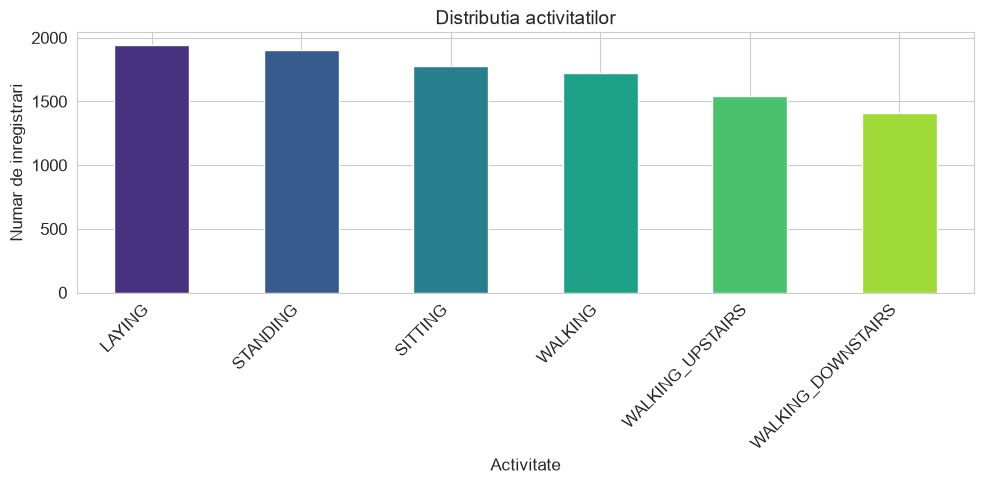

In [5]:
# Defalcarea fiecarei activitati
print(df['Activity'].value_counts())
print()
print('Procentaje:')
print((df['Activity'].value_counts(normalize=True) * 100).round(2))

# Vizualizare
fig, ax = plt.subplots(figsize=(10, 5))
df['Activity'].value_counts().plot(kind='bar', color=sns.color_palette('viridis', 6), ax=ax)
ax.set_title('Distributia activitatilor', fontsize=14)
ax.set_ylabel('Numar de inregistrari')
ax.set_xlabel('Activitate')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Codificarea etichetelor
Clasificatoarele Scikit learn nu vor accepta o matrice dispersată pentru coloana de predicție. Utilizăm `LabelEncoder` pentru a fit_transforma coloana 'Activity' și analizăm 5 valori aleatorii.

In [6]:
# Codificarea etichetei activitatii
le = LabelEncoder()
df['ActivityEncoded'] = le.fit_transform(df['Activity'])

print('Clasele codificate:', dict(zip(le.classes_, le.transform(le.classes_))))
print()
print('5 valori aleatorii:')
print(df[['Activity', 'ActivityEncoded']].sample(5, random_state=42))

Clasele codificate: {'LAYING': np.int64(0), 'SITTING': np.int64(1), 'STANDING': np.int64(2), 'WALKING': np.int64(3), 'WALKING_DOWNSTAIRS': np.int64(4), 'WALKING_UPSTAIRS': np.int64(5)}

5 valori aleatorii:
      Activity  ActivityEncoded
5804   WALKING                3
3688    LAYING                0
7360  STANDING                2
3437  STANDING                2
8193   WALKING                3


## Întrebarea 2

* Calculați corelațiile dintre variabilele dependente.
* Creați o histogramă a valorilor corelației
* Identificați cele care sunt cele mai corelate (fie pozitiv, fie negativ).

In [7]:
# Calcularea matricei de corelatii
feature_cols = df.columns[:-2]  # excludem 'Activity' si 'ActivityEncoded'
corr_matrix = df[feature_cols].corr()

# Extragem triunghiul superior (fara diagonala)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
upper_corr = corr_matrix.where(mask)
corr_values = upper_corr.stack().values

print(f'Numarul total de perechi de corelatii: {len(corr_values)}')
print(f'Corelatie medie (abs): {np.abs(corr_values).mean():.4f}')
print(f'Corelatie maxima: {corr_values.max():.4f}')
print(f'Corelatie minima: {corr_values.min():.4f}')

Numarul total de perechi de corelatii: 314721
Corelatie medie (abs): nan
Corelatie maxima: nan
Corelatie minima: nan


### Histograma corelațiilor (valoare absolută)

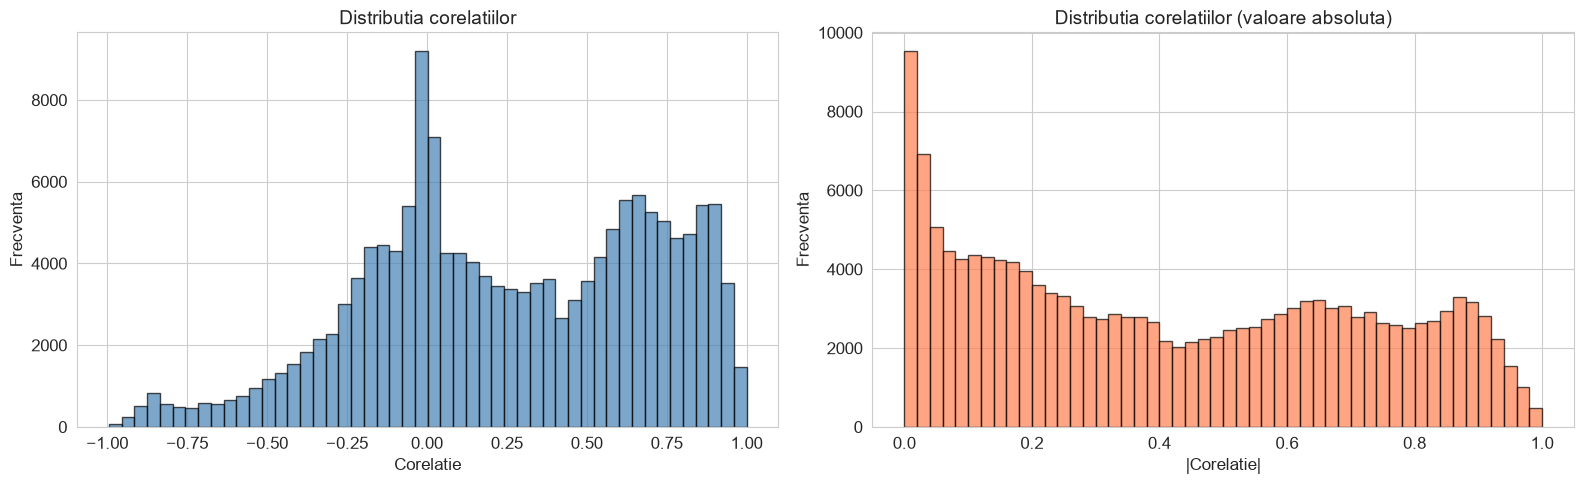

In [8]:
# Histograma valorilor absolute ale corelatiilor
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(corr_values, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Distributia corelatiilor', fontsize=14)
axes[0].set_xlabel('Corelatie')
axes[0].set_ylabel('Frecventa')

axes[1].hist(np.abs(corr_values), bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_title('Distributia corelatiilor (valoare absoluta)', fontsize=14)
axes[1].set_xlabel('|Corelatie|')
axes[1].set_ylabel('Frecventa')

plt.tight_layout()
plt.show()

In [9]:
# Cele mai corelate perechi de variabile
corr_pairs = upper_corr.stack().reset_index()
corr_pairs.columns = ['Feature_1', 'Feature_2', 'Correlation']
corr_pairs['AbsCorrelation'] = corr_pairs['Correlation'].abs()
corr_pairs_sorted = corr_pairs.sort_values('AbsCorrelation', ascending=False)

print('Top 10 cele mai corelate perechi (pozitiv sau negativ):')
print(corr_pairs_sorted.head(10).to_string(index=False))

Top 10 cele mai corelate perechi (pozitiv sau negativ):
              Feature_1                 Feature_2  Correlation  AbsCorrelation
   tBodyAccMag-energy()   tGravityAccMag-energy()          1.0             1.0
      tBodyAccMag-iqr()      tGravityAccMag-iqr()          1.0             1.0
  tBodyAccMag-entropy()  tGravityAccMag-entropy()          1.0             1.0
tBodyGyroJerkMag-mean()    tBodyGyroJerkMag-sma()          1.0             1.0
fBodyBodyGyroMag-mean()    fBodyBodyGyroMag-sma()          1.0             1.0
      tBodyAccMag-sma()      tGravityAccMag-sma()          1.0             1.0
 tBodyAccMag-arCoeff()1 tGravityAccMag-arCoeff()1          1.0             1.0
 tBodyAccMag-arCoeff()2 tGravityAccMag-arCoeff()2          1.0             1.0
      tBodyAccMag-min()      tGravityAccMag-min()          1.0             1.0
      tBodyAccMag-sma()     tGravityAccMag-mean()          1.0             1.0


## Întrebarea 3

* Împărțiți datele în seturi de instruire și de testare folosind `StratifiedShuffleSplit`.
* Comparați raportul claselor în ambele împărțiri.

In [10]:
# Pregatirea datelor
feature_cols = df.columns[:-2]  # excludem 'Activity' si 'ActivityEncoded'
X = df[feature_cols]
y = df['ActivityEncoded']

# StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)

for train_index, test_index in sss.split(X, y):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

print(f'Dimensiune set antrenare: {X_train.shape}')
print(f'Dimensiune set testare:   {X_test.shape}')

Dimensiune set antrenare: (7209, 561)
Dimensiune set testare:   (3090, 561)


In [11]:
# Compararea raportului claselor intre train si test
train_dist = y_train.value_counts(normalize=True).sort_index() * 100
test_dist = y_test.value_counts(normalize=True).sort_index() * 100

comparison = pd.DataFrame({
    'Activitate': le.classes_,
    'Train (%)': train_dist.values.round(2),
    'Test (%)': test_dist.values.round(2)
})
comparison['Diferenta (pp)'] = (comparison['Train (%)'] - comparison['Test (%)']).abs().round(2)
print(comparison.to_string(index=False))
print()
print('Distributiile sunt foarte similare, StratifiedShuffleSplit pastreaza raportul claselor.')

        Activitate  Train (%)  Test (%)  Diferenta (pp)
            LAYING      18.88     18.87            0.01
           SITTING      17.26     17.25            0.01
          STANDING      18.50     18.51            0.01
           WALKING      16.72     16.73            0.01
WALKING_DOWNSTAIRS      13.65     13.66            0.01
  WALKING_UPSTAIRS      15.00     14.98            0.02

Distributiile sunt foarte similare, StratifiedShuffleSplit pastreaza raportul claselor.


## Întrebarea 4

* Ajustați un model de regresie logistică fără regularizare folosind toate caracteristicile.
* Folosind validarea încrucișată, ajustați modelele folosind regularizarea L1 și L2.
* Stocați fiecare model.

In [12]:
# Model 1: Regresie logistica FARA regularizare
lr_no_reg = LogisticRegression(
    penalty=None,
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)
lr_no_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the opti

In [13]:
# Model 2: Regresie logistica cu regularizare L2 (cross-validation)
lr_l2 = LogisticRegressionCV(
    penalty='l2',
    solver='lbfgs',
    cv=3,
    max_iter=1000,
    random_state=42
)
lr_l2.fit(X_train, y_train)

,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"max_iter max_iter: int, default=100Maximum number of iterations of the optimization algorithm.",1000
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.Note that this only applies to the solver and not the cross-validationgenerator. See :term:`Glossary <random_state>` for details.",42
,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'warn'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choic

In [ ]:
# Model 3: Regresie logistica cu regularizare L1 (cross-validation)
from sklearn.multiclass import OneVsRestClassifier

lr_l1 = OneVsRestClassifier(
    LogisticRegressionCV(
        Cs=np.logspace(-2, 2, 5),
        penalty='l1',
        solver='liblinear',
        cv=3,
        max_iter=1000,
        random_state=42
    )
)
lr_l1.fit(X_train, y_train)

lr_l1.coef_ = np.vstack([est.coef_ for est in lr_l1.estimators_])
lr_l1.intercept_ = np.hstack([est.intercept_ for est in lr_l1.estimators_])

In [15]:
# Stocarea modelelor intr-un dictionar pentru acces usor
models = {
    'Fara regularizare': lr_no_reg,
    'L2 (Ridge)': lr_l2,
    'L1 (Lasso)': lr_l1
}
print('Toate cele 3 modele au fost stocate.')

Toate cele 3 modele au fost stocate.


## Întrebarea 5

Comparați mărimile coeficienților pentru fiecare dintre modele. Pregătiți șase diagrame separate pentru fiecare dintre coeficienții multi-clasă.

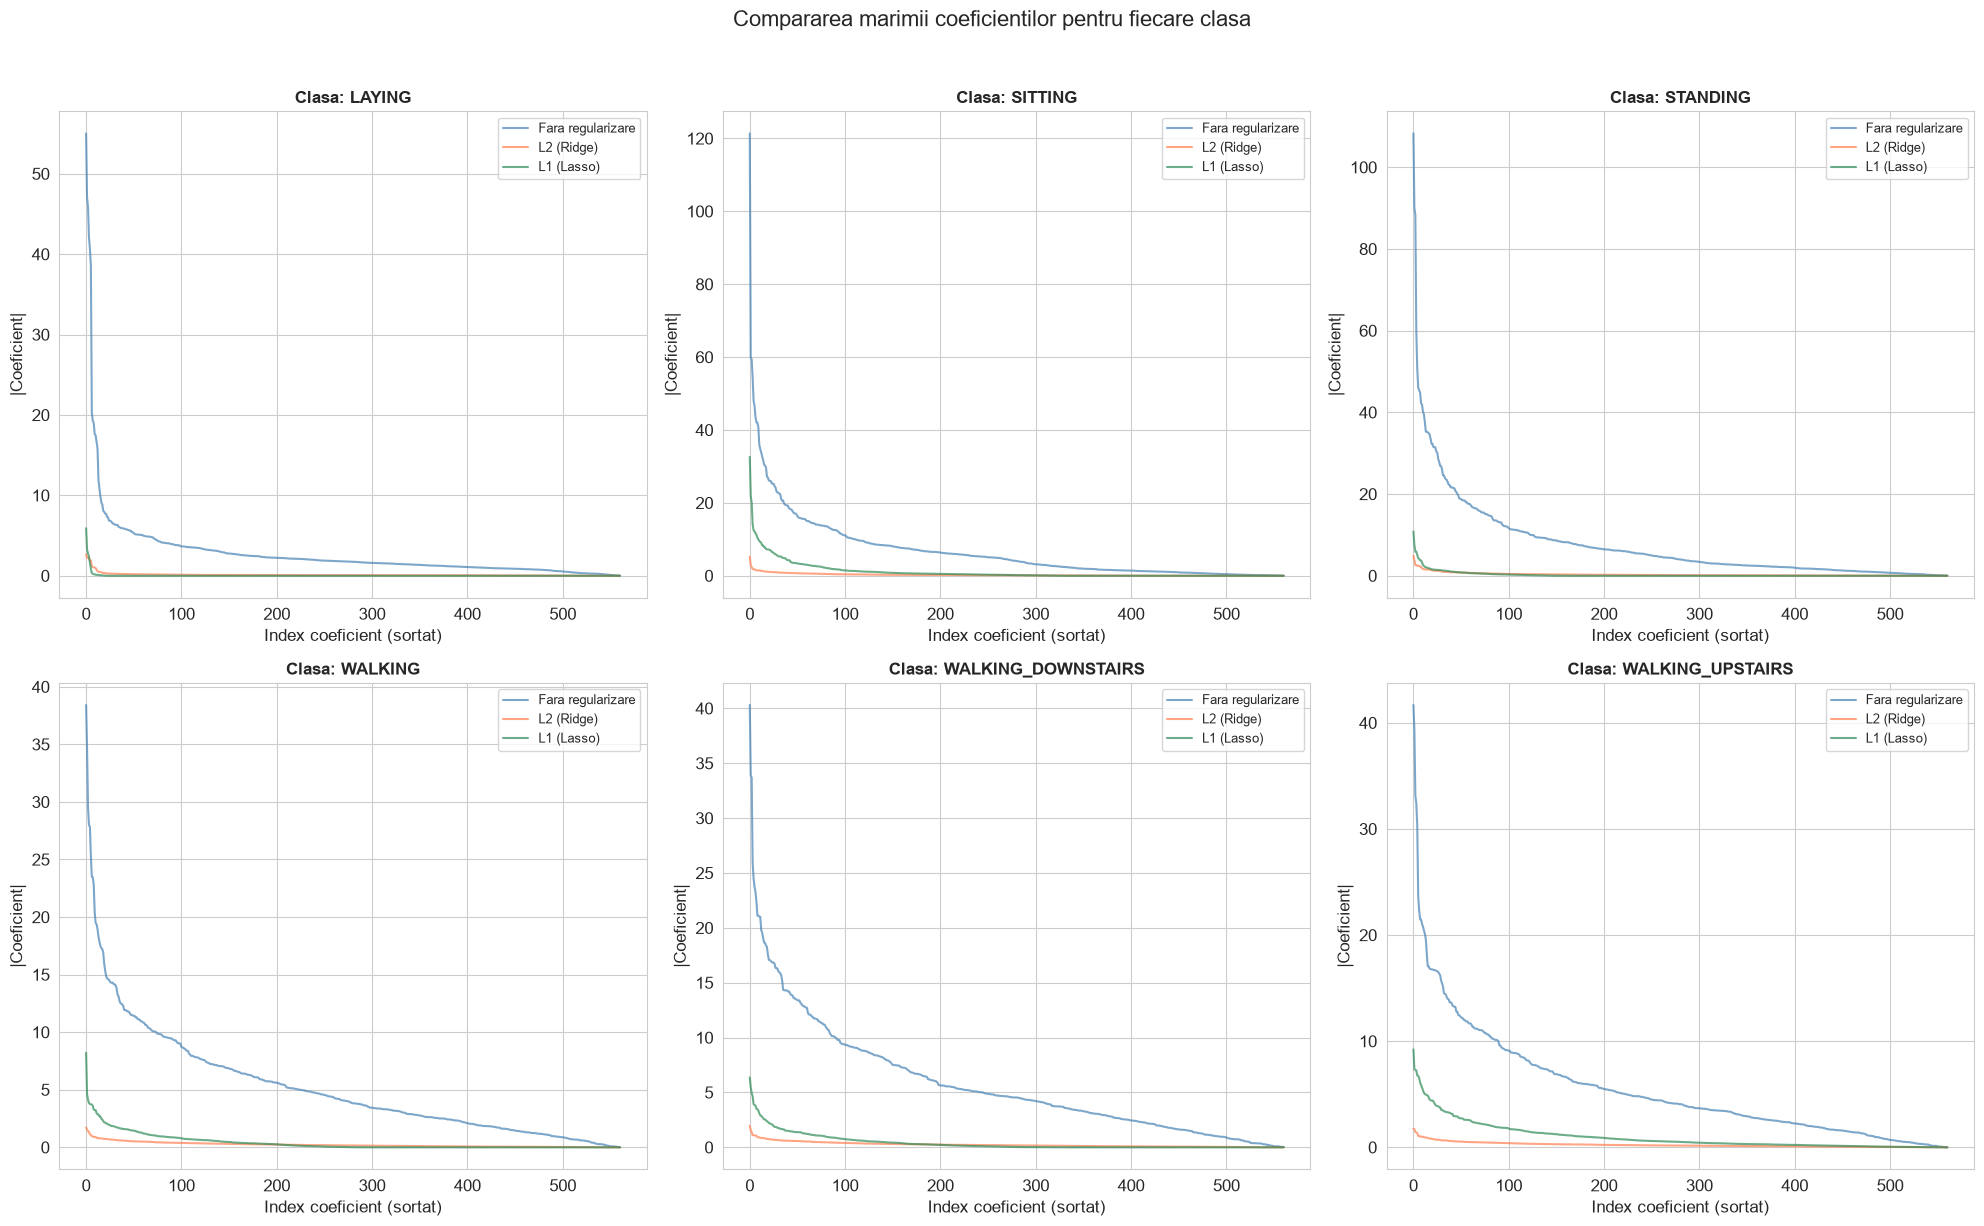

In [16]:
# Compararea coeficientilor pentru toate cele 6 clase
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

class_names = le.classes_
model_names = list(models.keys())
colors = ['steelblue', 'coral', 'seagreen']

for i, class_name in enumerate(class_names):
    ax = axes[i]
    for j, (name, model) in enumerate(models.items()):
        coefs = model.coef_[i]
        ax.plot(sorted(np.abs(coefs), reverse=True), 
                label=name, alpha=0.7, color=colors[j], linewidth=1.5)
    ax.set_title(f'Clasa: {class_name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Index coeficient (sortat)')
    ax.set_ylabel('|Coeficient|')
    ax.legend(fontsize=9)

plt.suptitle('Compararea marimii coeficientilor pentru fiecare clasa', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [17]:
# Statistici sumare despre coeficienti
header = f"{'Model':<25} {'Nr. coef. != 0':>15} {'Media |coef|':>15} {'Max |coef|':>12}"
print(header)
print('-' * 70)
for name, model in models.items():
    coefs = model.coef_
    n_nonzero = np.count_nonzero(coefs)
    total = coefs.size
    mean_abs = np.abs(coefs).mean()
    max_abs = np.abs(coefs).max()
    print(f'{name:<25} {n_nonzero:>7}/{total:<7} {mean_abs:>15.4f} {max_abs:>12.4f}')

print()
print('Observatie: L1 (Lasso) produce coeficienti mai rari (mai multi zerouri).')

Model                      Nr. coef. != 0    Media |coef|   Max |coef|
----------------------------------------------------------------------
Fara regularizare            3366/3366             5.6356     121.3759
L2 (Ridge)                   3366/3366             0.2271       5.2292
L1 (Lasso)                   1670/3366             0.5377      32.6268

Observatie: L1 (Lasso) produce coeficienti mai rari (mai multi zerouri).


## Întrebarea 6

* Preziceți și stocați clasa pentru fiecare model.
* De asemenea, stocați probabilitatea pentru clasa prezisă pentru fiecare model.

In [18]:
# Predictii si probabilitati pentru fiecare model
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    predictions[name] = y_pred
    probabilities[name] = y_prob
    print(f'{name}:')
    print(f'  Primele 5 predictii: {y_pred[:5]}')
    print(f'  Primele 5 probabilitati max: {y_prob.max(axis=1)[:5].round(4)}')
    print()

Fara regularizare:
  Primele 5 predictii: [3 5 3 1 0]
  Primele 5 probabilitati max: [1. 1. 1. 1. 1.]

L2 (Ridge):
  Primele 5 predictii: [3 5 3 1 0]
  Primele 5 probabilitati max: [1.     0.9997 0.9991 0.9978 0.9993]

L1 (Lasso):
  Primele 5 predictii: [3 5 3 1 0]
  Primele 5 probabilitati max: [0.9979 0.9992 0.9984 0.9932 1.    ]



## Întrebarea 7

Pentru fiecare model, calculați următoarele măsurători de eroare:

* acuratețe
* precizie
* recall
* fscore
* matricea de confuzie

Combinăm metricile multi-clasă folosind media ponderată (weighted average).

In [19]:
# Calculul metricilor de eroare pentru fiecare model
for name, model in models.items():
    y_pred = predictions[name]
    
    # Acuratete
    acc = accuracy_score(y_test, y_pred)
    
    # Precizie, Recall, F-score (weighted)
    precision, recall, fscore, support = score(y_test, y_pred, average='weighted')
    
    print(f'=== {name} ===')
    print(f'  Acuratete:  {acc:.4f}')
    print(f'  Precizie:   {precision:.4f}')
    print(f'  Recall:     {recall:.4f}')
    print(f'  F-score:    {fscore:.4f}')
    print()
    print('  Raport de clasificare detaliat:')
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print('-' * 70)
    print()

=== Fara regularizare ===
  Acuratete:  0.9809
  Precizie:   0.9809
  Recall:     0.9809
  F-score:    0.9809

  Raport de clasificare detaliat:
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       583
           SITTING       0.95      0.95      0.95       533
          STANDING       0.96      0.96      0.96       572
           WALKING       1.00      0.99      0.99       517
WALKING_DOWNSTAIRS       0.99      1.00      0.99       422
  WALKING_UPSTAIRS       0.99      0.99      0.99       463

          accuracy                           0.98      3090
         macro avg       0.98      0.98      0.98      3090
      weighted avg       0.98      0.98      0.98      3090

----------------------------------------------------------------------

=== L2 (Ridge) ===
  Acuratete:  0.9845
  Precizie:   0.9845
  Recall:     0.9845
  F-score:    0.9845

  Raport de clasificare detaliat:
                    precision    recall  f

In [20]:
# Tabel comparativ al modelelor
results = []
for name in models:
    y_pred = predictions[name]
    acc = accuracy_score(y_test, y_pred)
    precision, recall, fscore, _ = score(y_test, y_pred, average='weighted')
    results.append({
        'Model': name,
        'Acuratete': round(acc, 4),
        'Precizie': round(precision, 4),
        'Recall': round(recall, 4),
        'F-score': round(fscore, 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

            Model  Acuratete  Precizie  Recall  F-score
Fara regularizare     0.9809    0.9809  0.9809   0.9809
       L2 (Ridge)     0.9845    0.9845  0.9845   0.9845
       L1 (Lasso)     0.9835    0.9835  0.9835   0.9835


## Întrebarea 8

Afișați sau reprezentați grafic matricea de confuzie pentru fiecare model.

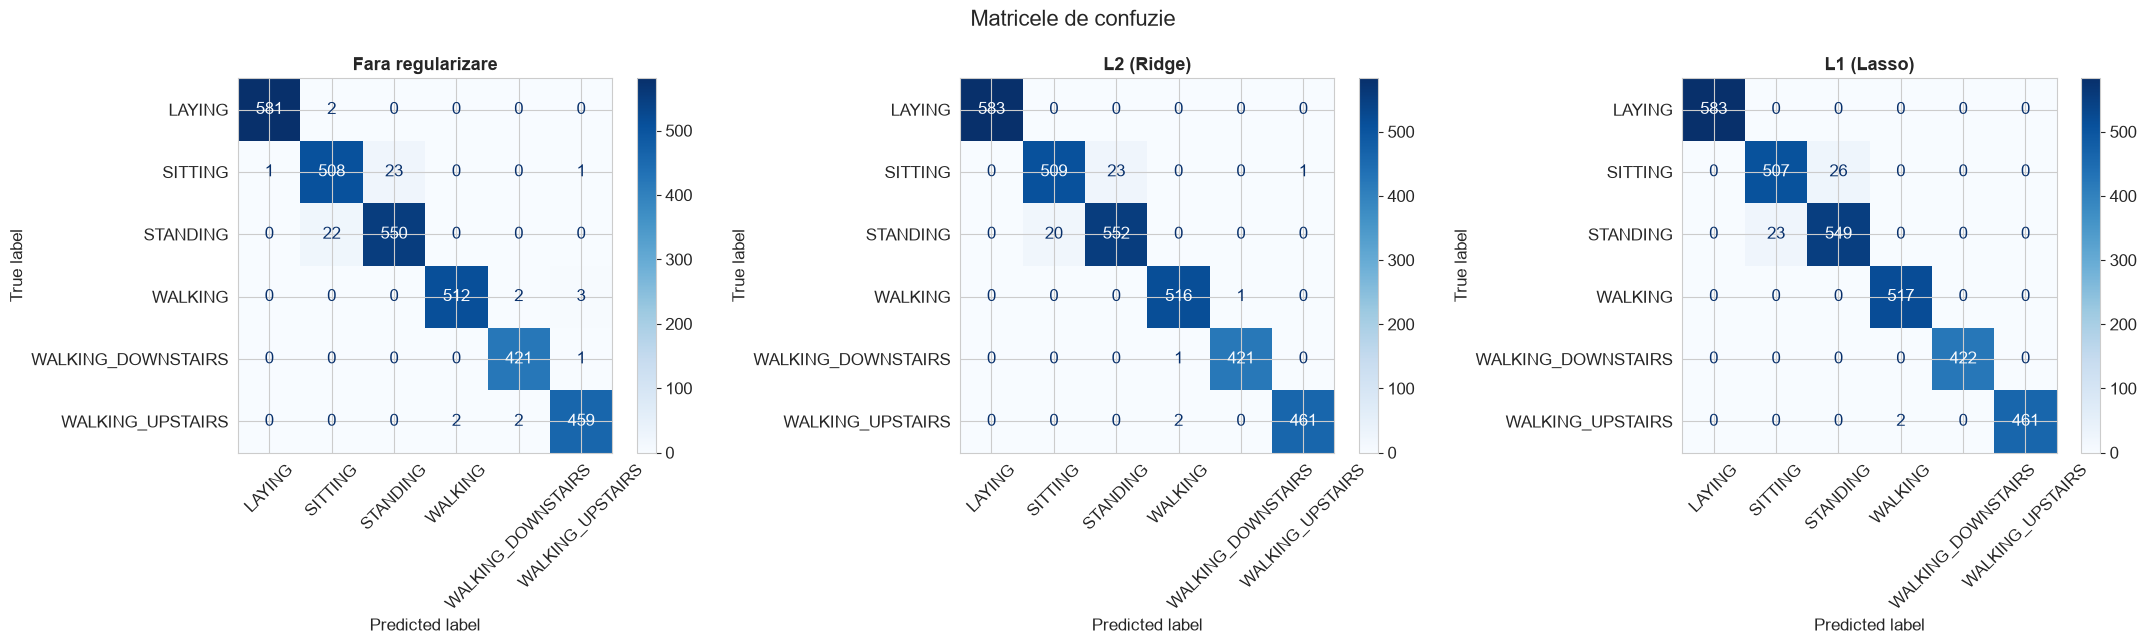

In [21]:
# Matricele de confuzie pentru fiecare model
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for idx, (name, model) in enumerate(models.items()):
    y_pred = predictions[name]
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    )
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d', xticks_rotation=45)
    axes[idx].set_title(f'{name}', fontsize=13, fontweight='bold')

plt.suptitle('Matricele de confuzie', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

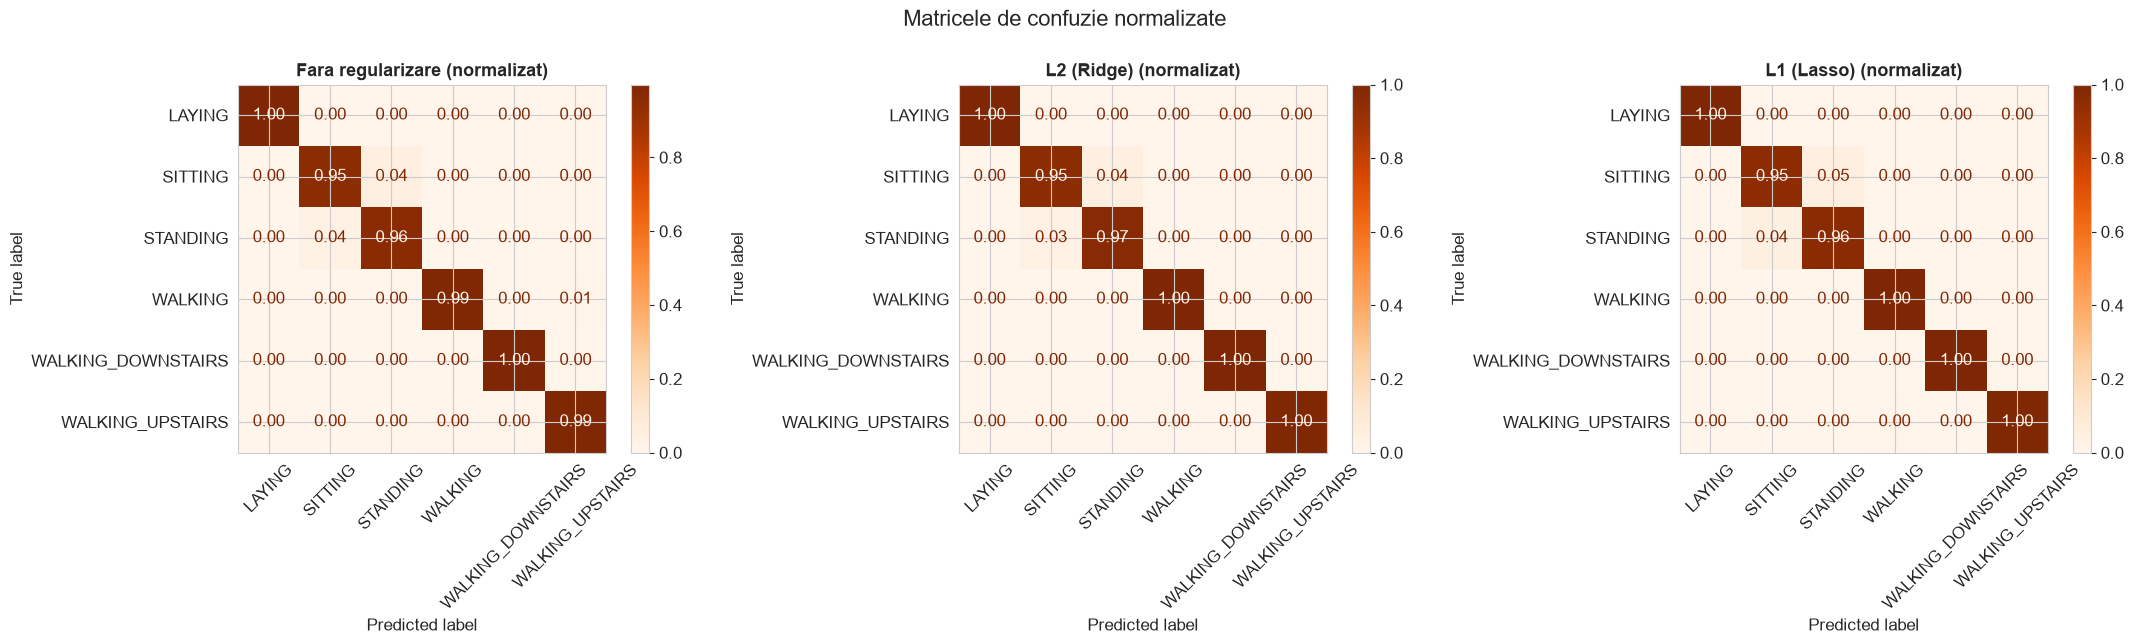

In [22]:
# Matricea de confuzie normalizata (procentual pe rand)
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for idx, (name, model) in enumerate(models.items()):
    y_pred = predictions[name]
    cm = confusion_matrix(y_test, y_pred, normalize='true')
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=le.classes_
    )
    disp.plot(ax=axes[idx], cmap='Oranges', values_format='.2f', xticks_rotation=45)
    axes[idx].set_title(f'{name} (normalizat)', fontsize=13, fontweight='bold')

plt.suptitle('Matricele de confuzie normalizate', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()